# Рекуррентный график цены биткоина

Рисунок из поста — это выход ячейки старого ноутбука с заголовком **Recurrence Graph of Bitcoin Price Patterns**.

Считалась она не по Yahoo. Перед ней ряд перезаписан ячейкой `pd.read_csv("../data/BTC_1d.csv")`. В выводе той ячейки 4622 строки, первая дата `2012-01-01`, первые свечи `4.39 / 4.58 / 4.39 / 4.58`. Это дневной Bitstamp BTC/USD. У Yahoo дневки начинаются только с 2014-09-17, поэтому график по `yf.download` получается другим окном.

Файл `data/BTC_1d.csv` собран с публичного OHLC Bitstamp так, чтобы совпали длина, даты и эти первые свечи. `Volume` в старой распечатке был в долларах, здесь объём в BTC: на график он не идёт, ячейка берёт только `Close`.

Параметры ячейки те же: `log(Close)`, `RecurrencePlot(threshold="point", percentage=3, dimension=1)`, белая цена с `alpha=0.2`, халвинги `2012-11-28`, `2016-07-09`, `2020-05-11`, `2024-04-20`, палитра `viridis`.

Цикл Херста из той ячейки убран: `hurst_exponent` там не определена, на рисунке её нет. Пустая нижняя строка `GridSpec` тоже убрана: на сохранённой картинке её нет, это был задел под Херста.

`interpolation_stage="data"` нужен только из-за matplotlib 3.11. Раньше матрица сжималась до палитры, и тонкая диагональ становилась бирюзовой серединой viridis. Сейчас по умолчанию смешивание идёт уже в RGB, и те же точки буреют.


## Данные


In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec
from pyts.image import RecurrencePlot

root = Path.cwd()
if not (root / "data" / "BTC_1d.csv").exists():
    root = root.parent
btc_path = root / "data" / "BTC_1d.csv"

btc_df = pd.read_csv(btc_path, parse_dates=["Date"], index_col="Date")
btc_df.index.name = "Date"
btc_data = btc_df.copy()

print(
    f"{btc_data.index.min().date()} — {btc_data.index.max().date()}, "
    f"строк: {len(btc_data)}"
)
btc_data.head()


2012-01-01 — 2024-08-26, строк: 4622


,Open,High,Low,Close,Volume
Date,,,,,
2012-01-01,4.39,4.58,4.39,4.58,95.317878
2012-01-02,4.58,5.00,4.58,5.00,21.602000
2012-01-03,5.00,5.00,5.00,5.00,19.048000
2012-01-04,5.32,5.32,5.14,5.29,88.037281
2012-01-05,4.93,5.57,4.93,5.57,107.233260


## График

Яркая точка: логарифмы цены в эти два дня близки, порог взят так, чтобы таких пар было 3%. Диагональ — день сам с собой. Жёлтые блоки — цена долго стояла в одном диапазоне. Белая линия — сама цена на логарифмической шкале. Красный пунктир — халвинг.


/workspace/output/bitcoin_recurrence_price_plot.png


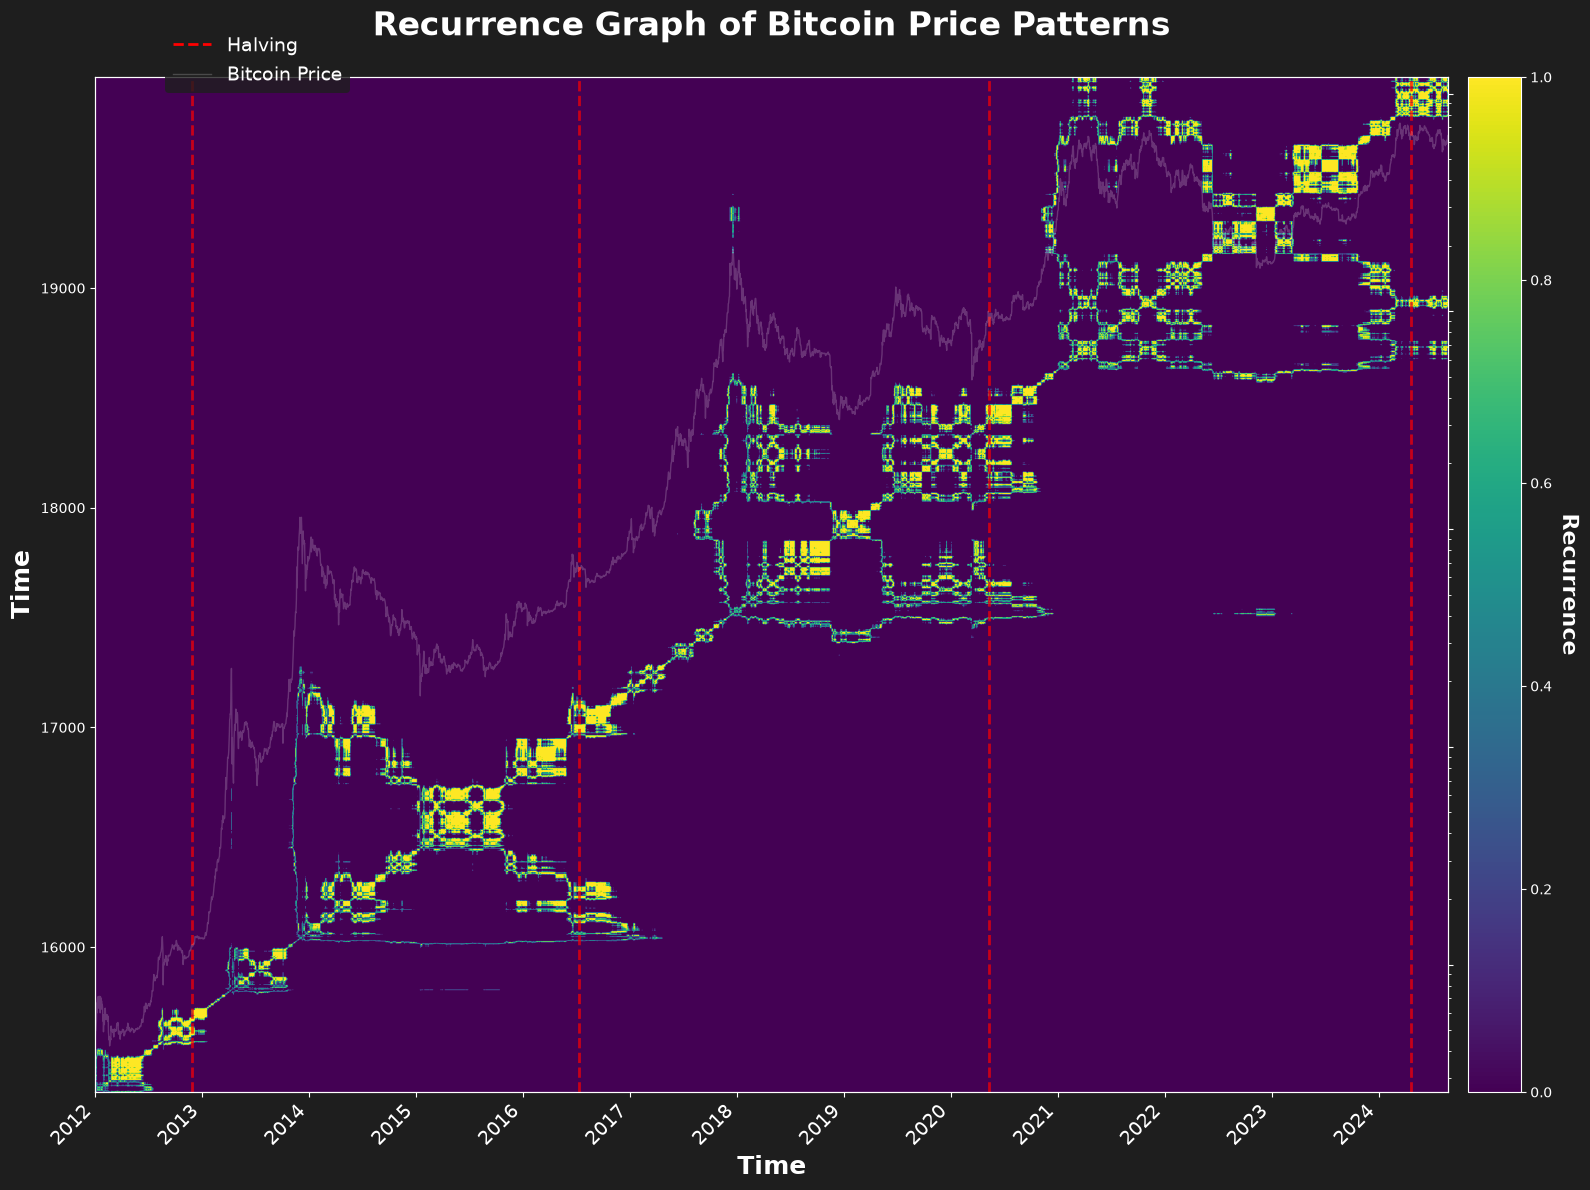

In [2]:
# .copy(): numpy 2 отдаёт массив только для чтения, numba внутри pyts его не принимает.
close = np.ascontiguousarray(np.log(btc_data["Close"].to_numpy(dtype=float)))
rp = RecurrencePlot(threshold="point", percentage=3, dimension=1)
X_rp = rp.fit_transform(close.reshape(1, -1).copy())

plt.style.use("dark_background")

fig = plt.figure(figsize=(16, 12))
gs = GridSpec(1, 20, figure=fig)
ax1 = fig.add_subplot(gs[0, :19])
cax = fig.add_subplot(gs[0, 19])
ax2 = ax1.twinx()

im = ax1.imshow(
    X_rp[0],
    cmap="viridis",
    aspect="auto",
    interpolation_stage="data",
    extent=[
        mdates.date2num(btc_data.index[0]),
        mdates.date2num(btc_data.index[-1]),
        mdates.date2num(btc_data.index[0]),
        mdates.date2num(btc_data.index[-1]),
    ],
    origin="lower",
)

ax1.set_title(
    "Recurrence Graph of Bitcoin Price Patterns",
    fontsize=24,
    fontweight="bold",
    pad=30,
)
ax1.set_xlabel("Time", fontsize=18, fontweight="bold")
ax1.set_ylabel("Time", fontsize=18, fontweight="bold")

ax2.plot(btc_data.index, btc_data["Close"], color="white", alpha=0.2, linewidth=1)
ax2.tick_params(axis="y", labelcolor="white", labelsize=14)
ax2.set_yscale("log")
ax2.set_yticklabels([])

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right", fontsize=14)

halving_dates = [
    datetime(2012, 11, 28),
    datetime(2016, 7, 9),
    datetime(2020, 5, 11),
    datetime(2024, 4, 20),
]
for date in halving_dates:
    if btc_data.index[0] <= date <= btc_data.index[-1]:
        ax1.axvline(x=mdates.date2num(date), color="red", linestyle="--", alpha=0.7, linewidth=2)

ax1.plot([], [], color="red", linestyle="--", label="Halving", linewidth=2)
ax2.plot([], [], color="white", label="Bitcoin Price", linewidth=1, alpha=0.2)
fig.legend(
    loc="upper left",
    bbox_to_anchor=(0.1, 0.98),
    fontsize=14,
    facecolor="#1E1E1E",
    edgecolor="none",
)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Recurrence", rotation=270, labelpad=20, fontsize=16, fontweight="bold")

fig.patch.set_facecolor("#1E1E1E")
plt.tight_layout()

out_path = root / "output" / "bitcoin_recurrence_price_plot.png"
out_path.parent.mkdir(exist_ok=True)
fig.savefig(out_path, dpi=100, bbox_inches="tight")
print(out_path)
plt.show()
